# DATASET LOADING

In [1]:
# ============================================================
# STEP 1: DATA COLLECTION
# Proposed SCO-MRBM Financial Fraud Detection Framework
# ============================================================

import pandas as pd
import os

# Dataset paths
numerical_path = r"E:\Projects\2_Financial Fraud\Dataset\numerical_fraud_dataset.csv"
text_path = r"E:\Projects\2_Financial Fraud\Dataset\text_fraud_dataset.csv"

print("=" * 70)
print("DATA COLLECTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify dataset availability
# ------------------------------------------------------------

for path in [numerical_path, text_path]:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Dataset not found: {path}")

print("\nBoth dataset files are available.")

# ------------------------------------------------------------
# 2. Load datasets into memory
# ------------------------------------------------------------

numerical_df = pd.read_csv(numerical_path)
text_df = pd.read_csv(text_path)

# ------------------------------------------------------------
# 3. Display dataset information
# ------------------------------------------------------------

def display_dataset_info(df, dataset_name):
    print("\n" + "=" * 70)
    print(f"{dataset_name}")
    print("=" * 70)

    print(f"Number of records : {df.shape[0]}")
    print(f"Number of columns : {df.shape[1]}")

    print("\nColumn Names:")
    print(df.columns.tolist())

    print("\nFirst 5 Records:")
    print(df.head().to_string(index=False))

    print("\nData Types:")
    print(df.dtypes.to_string())

    print("\nMissing Values:")
    print(df.isnull().sum().to_string())

    print("\nDuplicate Records:", df.duplicated().sum())

    print("\nMemory Usage:")
    print(f"{df.memory_usage(deep=True).sum() / (1024 ** 2):.2f} MB")


# Display numerical dataset information
display_dataset_info(
    numerical_df,
    "NUMERICAL FINANCIAL AND GOVERNANCE DATASET"
)

# Display textual dataset information
display_dataset_info(
    text_df,
    "TEXTUAL CORPORATE DISCLOSURE DATASET"
)

# ------------------------------------------------------------
# 4. Display fraud label distribution when available
# ------------------------------------------------------------

target_column = "Fraud_Label"

for name, df in [
    ("Numerical Dataset", numerical_df),
    ("Textual Dataset", text_df)
]:
    if target_column in df.columns:
        print(f"\nFraud Label Distribution - {name}")
        print(df[target_column].value_counts(dropna=False).to_string())

        print(f"\nFraud Label Percentage - {name}")
        print(
            (df[target_column].value_counts(normalize=True, dropna=False)
             * 100).round(2).to_string()
        )

# ------------------------------------------------------------
# 5. Final collection summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATA COLLECTION COMPLETED SUCCESSFULLY")
print("=" * 70)

print(f"Numerical dataset shape: {numerical_df.shape}")
print(f"Textual dataset shape  : {text_df.shape}")

DATA COLLECTION

Both dataset files are available.

NUMERICAL FINANCIAL AND GOVERNANCE DATASET
Number of records : 2000
Number of columns : 13

Column Names:
['Company_ID', 'ROA', 'ROE', 'Debt_to_Equity', 'Current_Ratio', 'Asset_Turnover', 'Revenue_Growth', 'Operating_Cash_Flow', 'Board_Size', 'Independent_Directors_Percent', 'Institutional_Ownership', 'Audit_Committee_Size', 'Fraud_Label']

First 5 Records:
 Company_ID       ROA       ROE  Debt_to_Equity  Current_Ratio  Asset_Turnover  Revenue_Growth  Operating_Cash_Flow  Board_Size  Independent_Directors_Percent  Institutional_Ownership  Audit_Committee_Size Fraud_Label
          1 -0.012730 -0.238294        2.902780       2.444771        1.828643       -0.026359         2.925838e+07          10                      36.292009                87.068420                     6    No Fraud
          2  0.275357 -0.253021        4.046618       1.017159        1.749479       -0.067088        -5.198046e+06          14                      21.

# PREPROCESSING

In [2]:
# ============================================================
# STEP 2: DATA PREPROCESSING
# SCO-MRBM Financial Fraud Detection Framework
# ============================================================

import os
import numpy as np
import pandas as pd
import re

from sklearn.preprocessing import RobustScaler
from sklearn.impute import SimpleImputer

# ------------------------------------------------------------
# 1. Dataset paths
# ------------------------------------------------------------

base_path = r"E:\Projects\2_Financial Fraud\Dataset"
output_path = r"E:\Projects\2_Financial Fraud\Output"
numerical_path = os.path.join(
    base_path, "numerical_fraud_dataset.csv"
)

text_path = os.path.join(
    base_path, "text_fraud_dataset.csv"
)

numerical_output = os.path.join(
    output_path, "preprocessed_numerical_fraud_dataset.csv"
)

text_output = os.path.join(
    output_path, "preprocessed_text_fraud_dataset.csv"
)

# ------------------------------------------------------------
# 2. Load datasets
# ------------------------------------------------------------

numerical_df = pd.read_csv(numerical_path)
text_df = pd.read_csv(text_path)

print("=" * 70)
print("DATA PREPROCESSING")
print("=" * 70)

print("\nOriginal Numerical Dataset:", numerical_df.shape)
print("Original Textual Dataset  :", text_df.shape)

# ------------------------------------------------------------
# 3. Numerical data preprocessing
# ------------------------------------------------------------

numerical_df = numerical_df.copy()

# Identify numerical predictor columns
exclude_columns = ["Company_ID", "Fraud_Label"]

numeric_features = [
    col for col in numerical_df.select_dtypes(
        include=np.number
    ).columns
    if col not in exclude_columns
]

# Convert infinite values to missing values
numerical_df[numeric_features] = (
    numerical_df[numeric_features]
    .replace([np.inf, -np.inf], np.nan)
)

# Handle missing values using median imputation
imputer = SimpleImputer(strategy="median")

numerical_df[numeric_features] = imputer.fit_transform(
    numerical_df[numeric_features]
)

# Adaptive IQR-based outlier clipping
for col in numeric_features:

    Q1 = numerical_df[col].quantile(0.25)
    Q3 = numerical_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    numerical_df[col] = numerical_df[col].clip(
        lower=lower_limit,
        upper=upper_limit
    )

# Robust scaling of numerical predictors
scaler = RobustScaler()

numerical_df[numeric_features] = scaler.fit_transform(
    numerical_df[numeric_features]
)

# Preserve Company_ID and Fraud_Label without scaling
print("\nNumerical preprocessing completed.")
print("Numerical features processed:", len(numeric_features))

# ------------------------------------------------------------
# 4. Textual data preprocessing
# ------------------------------------------------------------

text_df = text_df.copy()

text_columns = [
    "MDnA_Text",
    "Risk_Disclosure_Text",
    "Chairman_Message",
    "Financial_Term",
    "Governance_Term",
    "Sentiment_Word",
    "Risk_Term",
    "Strategy_Term"
]

# Check that all expected columns exist
missing_columns = [
    col for col in text_columns
    if col not in text_df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing expected text columns: {missing_columns}"
    )

# Handle missing text values and clean text
def clean_text(value):

    if pd.isna(value):
        return ""

    value = str(value).lower()

    # Remove HTML tags
    value = re.sub(r"<[^>]+>", " ", value)

    # Keep alphabetic words and spaces
    value = re.sub(r"[^a-z\s]", " ", value)

    # Normalize whitespace
    value = re.sub(r"\s+", " ", value).strip()

    return value


for col in text_columns:
    text_df[col] = text_df[col].apply(clean_text)

print("Textual preprocessing completed.")
print("Text columns processed:", len(text_columns))

# ------------------------------------------------------------
# 5. Check company IDs and labels
# ------------------------------------------------------------

print("\nCompany ID consistency:")
print(
    "Numerical IDs unique:",
    numerical_df["Company_ID"].is_unique
)

print(
    "Textual IDs unique:",
    text_df["Company_ID"].is_unique
)

print(
    "Company IDs match:",
    set(numerical_df["Company_ID"])
    == set(text_df["Company_ID"])
)

print(
    "Fraud labels match by Company_ID:",
    numerical_df.set_index("Company_ID")["Fraud_Label"]
    .sort_index().equals(
        text_df.set_index("Company_ID")["Fraud_Label"]
        .sort_index()
    )
)

# ------------------------------------------------------------
# 6. Final missing-value checks
# ------------------------------------------------------------

print("\nRemaining missing values in numerical data:",
      numerical_df.isnull().sum().sum())

print("Remaining missing values in textual data:",
      text_df.isnull().sum().sum())

# ------------------------------------------------------------
# 7. Save preprocessed datasets
# ------------------------------------------------------------

numerical_df.to_csv(numerical_output, index=False)
text_df.to_csv(text_output, index=False)

print("\n" + "=" * 70)
print("STEP 2 COMPLETED SUCCESSFULLY")
print("=" * 70)

print("\nPreprocessed numerical dataset:")
print(numerical_output)
print("Shape:", numerical_df.shape)
print(numerical_df.head())

print("\nPreprocessed textual dataset:")
print(text_output)
print("Shape:", text_df.shape)
print(text_df.head())

DATA PREPROCESSING

Original Numerical Dataset: (2000, 13)
Original Textual Dataset  : (2000, 10)

Numerical preprocessing completed.
Numerical features processed: 11
Textual preprocessing completed.
Text columns processed: 8

Company ID consistency:
Numerical IDs unique: True
Textual IDs unique: True
Company IDs match: True
Fraud labels match by Company_ID: True

Remaining missing values in numerical data: 0
Remaining missing values in textual data: 0

STEP 2 COMPLETED SUCCESSFULLY

Preprocessed numerical dataset:
E:\Projects\2_Financial Fraud\Output\preprocessed_numerical_fraud_dataset.csv
Shape: (2000, 13)
   Company_ID       ROA       ROE  Debt_to_Equity  Current_Ratio  \
0           1 -0.259077 -0.463922        0.163283       0.329564   
1           2  0.864875 -0.493500        0.636865      -0.626377   
2           3  0.438214  0.830603        0.545022       0.779817   
3           4  0.178114 -0.488344       -0.684925       0.258973   
4           5 -0.685350 -0.443348       -0.

# DATA SPLITTING

In [3]:

# ============================================================
#  DATASET SPLITTING
# SCO-MRBM Financial Fraud Detection Framework
# 70% Training | 15% Validation | 15% Testing
# ============================================================

import os
import pandas as pd

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. File paths
# ------------------------------------------------------------

base_path = r"E:\Projects\2_Financial Fraud\Output"

numerical_path = os.path.join(
    base_path, "preprocessed_numerical_fraud_dataset.csv"
)

text_path = os.path.join(
    base_path, "preprocessed_text_fraud_dataset.csv"
)

# ------------------------------------------------------------
# 2. Load preprocessed datasets
# ------------------------------------------------------------

numerical_df = pd.read_csv(numerical_path)
text_df = pd.read_csv(text_path)

print("=" * 70)
print(" DATASET SPLITTING")
print("=" * 70)

print("\nNumerical dataset shape:", numerical_df.shape)
print("Textual dataset shape  :", text_df.shape)

# ------------------------------------------------------------
# 3. Validate dataset consistency
# ------------------------------------------------------------

if numerical_df["Company_ID"].duplicated().any():
    raise ValueError("Duplicate Company_ID in numerical dataset.")

if text_df["Company_ID"].duplicated().any():
    raise ValueError("Duplicate Company_ID in textual dataset.")

if set(numerical_df["Company_ID"]) != set(text_df["Company_ID"]):
    raise ValueError("Company_ID values do not match.")

# Align textual rows with numerical rows
text_df = (
    text_df.set_index("Company_ID")
    .loc[numerical_df["Company_ID"]]
    .reset_index()
)

if not numerical_df["Fraud_Label"].equals(text_df["Fraud_Label"]):
    raise ValueError("Fraud labels do not match after alignment.")

# ------------------------------------------------------------
# 4. Create a common stratified split
# ------------------------------------------------------------

# Split company IDs to guarantee that the same companies
# belong to the same subset in both modalities.

company_ids = numerical_df["Company_ID"]
labels = numerical_df["Fraud_Label"]

# First split: 70% training and 30% temporary data
train_ids, temp_ids = train_test_split(
    company_ids,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Extract labels for the temporary subset
temp_labels = (
    numerical_df.set_index("Company_ID")
    .loc[temp_ids, "Fraud_Label"]
)

# Second split: 15% validation and 15% testing
val_ids, test_ids = train_test_split(
    temp_ids,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

# ------------------------------------------------------------
# 5. Generate numerical and textual subsets
# ------------------------------------------------------------

def split_by_ids(df, ids):
    return (
        df.set_index("Company_ID")
        .loc[list(ids)]
        .reset_index()
    )

numerical_train = split_by_ids(numerical_df, train_ids)
numerical_val = split_by_ids(numerical_df, val_ids)
numerical_test = split_by_ids(numerical_df, test_ids)

text_train = split_by_ids(text_df, train_ids)
text_val = split_by_ids(text_df, val_ids)
text_test = split_by_ids(text_df, test_ids)

# ------------------------------------------------------------
# 6. Verify sizes and prevent overlap
# ------------------------------------------------------------

print("\nDataset split summary")
print("-" * 70)

splits = {
    "Training": train_ids,
    "Validation": val_ids,
    "Testing": test_ids
}

for name, ids in splits.items():
    print(f"{name:12s}: {len(ids):4d} records "
          f"({len(ids) / len(company_ids) * 100:.1f}%)")

assert len(train_ids) == 1400
assert len(val_ids) == 300
assert len(test_ids) == 300

assert set(train_ids).isdisjoint(set(val_ids))
assert set(train_ids).isdisjoint(set(test_ids))
assert set(val_ids).isdisjoint(set(test_ids))

assert len(set(train_ids) | set(val_ids) | set(test_ids)) == 2000

# Verify aligned IDs across modalities
for name, num_df, txt_df in [
    ("Training", numerical_train, text_train),
    ("Validation", numerical_val, text_val),
    ("Testing", numerical_test, text_test)
]:
    assert num_df["Company_ID"].equals(txt_df["Company_ID"])
    assert num_df["Fraud_Label"].equals(txt_df["Fraud_Label"])

# ------------------------------------------------------------
# 7. Print class distributions
# ------------------------------------------------------------

for name, df in [
    ("Training", numerical_train),
    ("Validation", numerical_val),
    ("Testing", numerical_test)
]:
    print(f"\n{name} class distribution:")
    print(df["Fraud_Label"].value_counts().to_string())

    print("\nClass percentages:")
    print(
        (df["Fraud_Label"].value_counts(normalize=True) * 100)
        .round(2).to_string()
    )

# ------------------------------------------------------------
# 8. Save split datasets
# ------------------------------------------------------------

output_files = {
    "numerical_train": numerical_train,
    "numerical_validation": numerical_val,
    "numerical_test": numerical_test,
    "text_train": text_train,
    "text_validation": text_val,
    "text_test": text_test
}

for name, df in output_files.items():
    output_path = os.path.join(
        base_path, f"{name}_fraud_dataset.csv"
    )
    df.to_csv(output_path, index=False)
    print(f"Saved: {output_path}")

# ------------------------------------------------------------
# 9. Final confirmation
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Training records  :", len(train_ids))
print("Validation records:", len(val_ids))
print("Testing records   :", len(test_ids))

 DATASET SPLITTING

Numerical dataset shape: (2000, 13)
Textual dataset shape  : (2000, 10)

Dataset split summary
----------------------------------------------------------------------
Training    : 1400 records (70.0%)
Validation  :  300 records (15.0%)
Testing     :  300 records (15.0%)

Training class distribution:
Fraud_Label
No Fraud    1124
Fraud        276

Class percentages:
Fraud_Label
No Fraud    80.29
Fraud       19.71

Validation class distribution:
Fraud_Label
No Fraud    241
Fraud        59

Class percentages:
Fraud_Label
No Fraud    80.33
Fraud       19.67

Testing class distribution:
Fraud_Label
No Fraud    241
Fraud        59

Class percentages:
Fraud_Label
No Fraud    80.33
Fraud       19.67
Saved: E:\Projects\2_Financial Fraud\Output\numerical_train_fraud_dataset.csv
Saved: E:\Projects\2_Financial Fraud\Output\numerical_validation_fraud_dataset.csv
Saved: E:\Projects\2_Financial Fraud\Output\numerical_test_fraud_dataset.csv
Saved: E:\Projects\2_Financial Fraud\Outpu

# FEATURE EXTRACTION

# PCA-BASED NUMERICAL FEATURE EXTRACTION

In [5]:
# ================================================================
# NUMERICAL FEATURE EXTRACTION USING PCA
# ================================================================

import os
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA

print("=" * 70)
print("NUMERICAL FEATURE EXTRACTION USING PCA")
print("=" * 70)

# ------------------------------------------------
# 1. Define input and output paths
# ------------------------------------------------
output_dir = r"E:\Projects\2_Financial Fraud\Output"
os.makedirs(output_dir, exist_ok=True)

train_path = os.path.join(
    output_dir, "numerical_train_fraud_dataset.csv"
)
val_path = os.path.join(
    output_dir, "numerical_validation_fraud_dataset.csv"
)
test_path = os.path.join(
    output_dir, "numerical_test_fraud_dataset.csv"
)

# ------------------------------------------------
# 2. Load the datasets
# ------------------------------------------------
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("\nTraining dataset  :", train_df.shape)
print("Validation dataset:", val_df.shape)
print("Testing dataset   :", test_df.shape)

# ------------------------------------------------
# 3. Identify numerical predictor features
# ------------------------------------------------
exclude_cols = ["Company_ID", "Fraud_Label"]

feature_cols = [
    col for col in train_df.columns
    if col not in exclude_cols
    and pd.api.types.is_numeric_dtype(train_df[col])
]

print("\nOriginal numerical feature count:", len(feature_cols))
print("Features used for PCA:")
print(feature_cols)

# ------------------------------------------------
# 4. Validate consistent feature columns
# ------------------------------------------------
for name, df in [
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing_cols = [col for col in feature_cols if col not in df.columns]

    if missing_cols:
        raise ValueError(
            f"{name} dataset is missing features: {missing_cols}"
        )

if not feature_cols:
    raise ValueError("No numerical predictor features were found.")

# ------------------------------------------------
# 5. Prepare feature matrices
# ------------------------------------------------
X_train = train_df[feature_cols].copy()
X_val = val_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

# Handle non-finite values using training-set medians.
# The same training medians are applied to validation/test.
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)
X_test = X_test.replace([np.inf, -np.inf], np.nan)

train_medians = X_train.median().fillna(0)

X_train = X_train.fillna(train_medians)
X_val = X_val.fillna(train_medians)
X_test = X_test.fillna(train_medians)

# ------------------------------------------------
# 6. Fit PCA on training data only
# ------------------------------------------------
# Retain enough components to explain at least 95%
# of the training data's variance.
pca = PCA(n_components=0.95, svd_solver="full")

X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)
X_test_pca = pca.transform(X_test)

print("\nPCA completed successfully.")

print("Retained principal components:", pca.n_components_)
print(
    "Cumulative explained variance:",
    round(pca.explained_variance_ratio_.sum(), 4)
)
print(
    "Explained variance percentage:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# ------------------------------------------------
# 7. Create PCA output DataFrames
# ------------------------------------------------
pc_cols = [
    f"PC{i+1}" for i in range(pca.n_components_)
]

def create_pca_dataframe(original_df, transformed_data):
    result = pd.DataFrame(
        transformed_data,
        columns=pc_cols,
        index=original_df.index
    )

    # Preserve the identifier and target
    result.insert(
        0, "Company_ID", original_df["Company_ID"].values
    )
    result["Fraud_Label"] = original_df["Fraud_Label"].values

    return result

train_pca_df = create_pca_dataframe(train_df, X_train_pca)
val_pca_df = create_pca_dataframe(val_df, X_val_pca)
test_pca_df = create_pca_dataframe(test_df, X_test_pca)

# ------------------------------------------------
# 8. Save PCA datasets
# ------------------------------------------------
output_files = {
    "Training": (
        train_pca_df,
        "pca_numerical_train_fraud_dataset.csv"
    ),
    "Validation": (
        val_pca_df,
        "pca_numerical_validation_fraud_dataset.csv"
    ),
    "Testing": (
        test_pca_df,
        "pca_numerical_test_fraud_dataset.csv"
    )
}

for name, (df, filename) in output_files.items():
    save_path = os.path.join(output_dir, filename)
    df.to_csv(save_path, index=False)

    print(f"\n{name} PCA dataset saved:")
    print("Path :", save_path)
    print("Shape:", df.shape)

# ------------------------------------------------
# 9. Display explained variance summary
# ------------------------------------------------
variance_summary = pd.DataFrame({
    "Principal_Component": pc_cols,
    "Explained_Variance_Ratio": pca.explained_variance_ratio_,
    "Explained_Variance_Percentage":
        pca.explained_variance_ratio_ * 100,
    "Cumulative_Variance_Percentage":
        np.cumsum(pca.explained_variance_ratio_) * 100
})

print("\nExplained Variance Summary:")
print(variance_summary.round(4).to_string(index=False))

variance_path = os.path.join(
    output_dir, "pca_explained_variance_summary.csv"
)
variance_summary.to_csv(variance_path, index=False)

print("\nVariance summary saved:", variance_path)

# ------------------------------------------------
# 10. Display PCA samples correctly
# ------------------------------------------------
print("\nFirst five training PCA records:")
print(train_pca_df.head().to_string(index=False))

print("\nFirst five validation PCA records:")
print(val_pca_df.head().to_string(index=False))

print("\nFirst five testing PCA records:")
print(test_pca_df.head().to_string(index=False))

# ------------------------------------------------
# 11. Final summary
# ------------------------------------------------
print("\n" + "=" * 70)
print("PCA FEATURE EXTRACTION COMPLETED SUCCESSFULLY")
print("=" * 70)

print("Training PCA shape  :", X_train_pca.shape)
print("Validation PCA shape:", X_val_pca.shape)
print("Testing PCA shape   :", X_test_pca.shape)

print("\nAll PCA output files are saved in:")
print(output_dir)
print("=" * 70)


NUMERICAL FEATURE EXTRACTION USING PCA

Training dataset  : (1400, 13)
Validation dataset: (300, 13)
Testing dataset   : (300, 13)

Original numerical feature count: 11
Features used for PCA:
['ROA', 'ROE', 'Debt_to_Equity', 'Current_Ratio', 'Asset_Turnover', 'Revenue_Growth', 'Operating_Cash_Flow', 'Board_Size', 'Independent_Directors_Percent', 'Institutional_Ownership', 'Audit_Committee_Size']

PCA completed successfully.
Retained principal components: 11
Cumulative explained variance: 1.0
Explained variance percentage: 100.0 %

Training PCA dataset saved:
Path : E:\Projects\2_Financial Fraud\Output\pca_numerical_train_fraud_dataset.csv
Shape: (1400, 13)

Validation PCA dataset saved:
Path : E:\Projects\2_Financial Fraud\Output\pca_numerical_validation_fraud_dataset.csv
Shape: (300, 13)

Testing PCA dataset saved:
Path : E:\Projects\2_Financial Fraud\Output\pca_numerical_test_fraud_dataset.csv
Shape: (300, 13)

Explained Variance Summary:
Principal_Component  Explained_Variance_Ratio

# TEXT FEATURE EXTRACTION USING WORD2VEC

In [7]:
# ================================================================
#  TEXT FEATURE EXTRACTION USING WORD2VEC
# Financial Fraud Detection Framework
# ================================================================

import os
import re
import numpy as np
import pandas as pd

from gensim.models import Word2Vec

print("=" * 70)
print("TEXT FEATURE EXTRACTION USING WORD2VEC")
print("=" * 70)

# ------------------------------------------------
# 1. Define paths
# ------------------------------------------------
output_dir = r"E:\Projects\2_Financial Fraud\Output"
os.makedirs(output_dir, exist_ok=True)

train_path = os.path.join(
    output_dir, "text_train_fraud_dataset.csv"
)
val_path = os.path.join(
    output_dir, "text_validation_fraud_dataset.csv"
)
test_path = os.path.join(
    output_dir, "text_test_fraud_dataset.csv"
)

# ------------------------------------------------
# 2. Load text datasets
# ------------------------------------------------
train_df = pd.read_csv(train_path)
val_df = pd.read_csv(val_path)
test_df = pd.read_csv(test_path)

print("\nTraining dataset  :", train_df.shape)
print("Validation dataset:", val_df.shape)
print("Testing dataset   :", test_df.shape)

# ------------------------------------------------
# 3. Identify text columns
# ------------------------------------------------
exclude_cols = ["Company_ID", "Fraud_Label"]

text_cols = [
    col for col in train_df.columns
    if col not in exclude_cols
]

if not text_cols:
    raise ValueError("No text columns were found in the training dataset.")

for name, df in [
    ("Validation", val_df),
    ("Testing", test_df)
]:
    missing_cols = [col for col in text_cols if col not in df.columns]
    if missing_cols:
        raise ValueError(
            f"{name} dataset is missing columns: {missing_cols}"
        )

print("\nText columns used:")
print(text_cols)

# ------------------------------------------------
# 4. Convert each company's text into tokens
# ------------------------------------------------
def tokenize_text(value):
    """Convert text to lowercase word tokens."""
    if pd.isna(value):
        return []

    text = str(value).lower()
    tokens = re.findall(r"\b[a-z]+(?:'[a-z]+)?\b", text)

    return tokens


def combine_row_text(row):
    """Combine all text fields for one company."""
    combined_tokens = []

    for col in text_cols:
        combined_tokens.extend(tokenize_text(row[col]))

    return combined_tokens


train_sentences = [
    combine_row_text(row)
    for _, row in train_df.iterrows()
]

val_sentences = [
    combine_row_text(row)
    for _, row in val_df.iterrows()
]

test_sentences = [
    combine_row_text(row)
    for _, row in test_df.iterrows()
]

print("\nText tokenization completed.")
print("Training text records  :", len(train_sentences))
print("Validation text records:", len(val_sentences))
print("Testing text records   :", len(test_sentences))

# ------------------------------------------------
# 5. Train Word2Vec using training text only
# ------------------------------------------------
VECTOR_SIZE = 100
WINDOW_SIZE = 5
MIN_COUNT = 1
EPOCHS = 30
RANDOM_SEED = 42

nonempty_train_sentences = [
    tokens for tokens in train_sentences if tokens
]

if not nonempty_train_sentences:
    raise ValueError(
        "No tokens were found in the training text. "
        "Check the text columns and their contents."
    )

word2vec_model = Word2Vec(
    sentences=nonempty_train_sentences,
    vector_size=VECTOR_SIZE,
    window=WINDOW_SIZE,
    min_count=MIN_COUNT,
    workers=1,
    sg=1,
    seed=RANDOM_SEED,
    epochs=EPOCHS
)

print("\nWord2Vec training completed.")
print("Vector size :", VECTOR_SIZE)
print("Window size :", WINDOW_SIZE)
print("Minimum count:", MIN_COUNT)
print("Training epochs:", EPOCHS)
print("Vocabulary size:", len(word2vec_model.wv))

# Save the trained model
model_path = os.path.join(
    output_dir, "word2vec_financial_fraud.model"
)
word2vec_model.save(model_path)

print("Word2Vec model saved:", model_path)

# ------------------------------------------------
# 6. Convert tokens into company-level embeddings
# ------------------------------------------------
def create_document_embedding(tokens, model, vector_size):
    """
    Average the Word2Vec vectors for all known tokens
    belonging to one company.
    """
    vectors = [
        model.wv[token]
        for token in tokens
        if token in model.wv
    ]

    if not vectors:
        return np.zeros(vector_size, dtype=np.float32)

    return np.mean(vectors, axis=0).astype(np.float32)


def create_embedding_matrix(sentences, model, vector_size):
    return np.vstack([
        create_document_embedding(tokens, model, vector_size)
        for tokens in sentences
    ])


X_train_text = create_embedding_matrix(
    train_sentences, word2vec_model, VECTOR_SIZE
)

X_val_text = create_embedding_matrix(
    val_sentences, word2vec_model, VECTOR_SIZE
)

X_test_text = create_embedding_matrix(
    test_sentences, word2vec_model, VECTOR_SIZE
)

print("\nText embeddings created successfully.")
print("Training embedding shape  :", X_train_text.shape)
print("Validation embedding shape:", X_val_text.shape)
print("Testing embedding shape   :", X_test_text.shape)

# ------------------------------------------------
# 7. Create output DataFrames
# ------------------------------------------------
embedding_cols = [
    f"Word2Vec_{i+1}"
    for i in range(VECTOR_SIZE)
]


def create_embedding_dataframe(original_df, embeddings):
    embedding_df = pd.DataFrame(
        embeddings,
        columns=embedding_cols,
        index=original_df.index
    )

    # Preserve company identifier and target
    embedding_df.insert(
        0, "Company_ID", original_df["Company_ID"].values
    )

    embedding_df["Fraud_Label"] = (
        original_df["Fraud_Label"].values
    )

    return embedding_df


train_embedding_df = create_embedding_dataframe(
    train_df, X_train_text
)

val_embedding_df = create_embedding_dataframe(
    val_df, X_val_text
)

test_embedding_df = create_embedding_dataframe(
    test_df, X_test_text
)

# ------------------------------------------------
# 8. Save the embedding datasets
# ------------------------------------------------
output_files = [
    (
        train_embedding_df,
        "word2vec_text_train_fraud_dataset.csv",
        "Training"
    ),
    (
        val_embedding_df,
        "word2vec_text_validation_fraud_dataset.csv",
        "Validation"
    ),
    (
        test_embedding_df,
        "word2vec_text_test_fraud_dataset.csv",
        "Testing"
    )
]

for df, filename, name in output_files:
    save_path = os.path.join(output_dir, filename)
    df.to_csv(save_path, index=False)

    print(f"\n{name} embedding dataset saved:")
    print("Path :", save_path)
    print("Shape:", df.shape)

# ------------------------------------------------
# 9. Check zero-vector records
# ------------------------------------------------
def count_zero_embeddings(embedding_matrix):
    return int(
        np.all(np.isclose(embedding_matrix, 0), axis=1).sum()
    )


print("\nZero-vector summary:")
print(
    "Training zero vectors  :",
    count_zero_embeddings(X_train_text)
)
print(
    "Validation zero vectors:",
    count_zero_embeddings(X_val_text)
)
print(
    "Testing zero vectors   :",
    count_zero_embeddings(X_test_text)
)

# ------------------------------------------------
# 10. Display sample embeddings
# ------------------------------------------------
print("\nFirst five training embeddings:")
print(train_embedding_df.head())

print("\nFirst five validation embeddings:")
print(val_embedding_df.head())

print("\nFirst five testing embeddings:")
print(test_embedding_df.head())

# ------------------------------------------------
# 11. Final summary
# ------------------------------------------------
print("\n" + "=" * 70)
print("WORD2VEC TEXT FEATURE EXTRACTION COMPLETED")
print("=" * 70)

print("Training records  :", len(train_embedding_df))
print("Validation records:", len(val_embedding_df))
print("Testing records   :", len(test_embedding_df))
print("Embedding dimensions:", VECTOR_SIZE)

print("\nOutput directory:")
print(output_dir)


TEXT FEATURE EXTRACTION USING WORD2VEC

Training dataset  : (1400, 10)
Validation dataset: (300, 10)
Testing dataset   : (300, 10)

Text columns used:
['MDnA_Text', 'Risk_Disclosure_Text', 'Chairman_Message', 'Financial_Term', 'Governance_Term', 'Sentiment_Word', 'Risk_Term', 'Strategy_Term']

Text tokenization completed.
Training text records  : 1400
Validation text records: 300
Testing text records   : 300

Word2Vec training completed.
Vector size : 100
Window size : 5
Minimum count: 1
Training epochs: 30
Vocabulary size: 104
Word2Vec model saved: E:\Projects\2_Financial Fraud\Output\word2vec_financial_fraud.model

Text embeddings created successfully.
Training embedding shape  : (1400, 100)
Validation embedding shape: (300, 100)
Testing embedding shape   : (300, 100)

Training embedding dataset saved:
Path : E:\Projects\2_Financial Fraud\Output\word2vec_text_train_fraud_dataset.csv
Shape: (1400, 102)

Validation embedding dataset saved:
Path : E:\Projects\2_Financial Fraud\Output\wo

# FEATURE FUSION

In [8]:
# ================================================================
# MULTIMODAL FEATURE FUSION
# PCA Numerical Features + Word2Vec Text Embeddings
# Financial Fraud Detection Framework
# ================================================================

import os
import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 6: MULTIMODAL FEATURE FUSION")
print("=" * 75)

# ------------------------------------------------
# 1. Define output directory
# ------------------------------------------------
output_dir = r"E:\Projects\2_Financial Fraud\Output"
os.makedirs(output_dir, exist_ok=True)

# ------------------------------------------------
# 2. Define input files
# ------------------------------------------------
files = {
    "train_pca": "pca_numerical_train_fraud_dataset.csv",
    "val_pca": "pca_numerical_validation_fraud_dataset.csv",
    "test_pca": "pca_numerical_test_fraud_dataset.csv",

    "train_text": "word2vec_text_train_fraud_dataset.csv",
    "val_text": "word2vec_text_validation_fraud_dataset.csv",
    "test_text": "word2vec_text_test_fraud_dataset.csv"
}

# ------------------------------------------------
# 3. Load PCA and Word2Vec datasets
# ------------------------------------------------
datasets = {}

for key, filename in files.items():
    path = os.path.join(output_dir, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(
            f"Required file not found: {path}"
        )

    datasets[key] = pd.read_csv(path)
    print(f"\nLoaded {filename}: {datasets[key].shape}")

train_pca = datasets["train_pca"]
val_pca = datasets["val_pca"]
test_pca = datasets["test_pca"]

train_text = datasets["train_text"]
val_text = datasets["val_text"]
test_text = datasets["test_text"]

# ------------------------------------------------
# 4. Define feature columns
# ------------------------------------------------
id_col = "Company_ID"
target_col = "Fraud_Label"

required_cols = [id_col, target_col]

for name, df in datasets.items():
    missing = [col for col in required_cols if col not in df.columns]

    if missing:
        raise ValueError(
            f"{name} is missing required columns: {missing}"
        )

    if df[id_col].duplicated().any():
        raise ValueError(
            f"Duplicate Company_ID values found in {name}."
        )

pca_cols = [
    col for col in train_pca.columns
    if col not in [id_col, target_col]
]

text_cols = [
    col for col in train_text.columns
    if col not in [id_col, target_col]
]

if not pca_cols:
    raise ValueError("No PCA feature columns found.")

if not text_cols:
    raise ValueError("No Word2Vec embedding columns found.")

# Confirm that validation and testing use the same feature schema.
for name, df in [
    ("Validation PCA", val_pca),
    ("Testing PCA", test_pca)
]:
    if [c for c in df.columns if c not in required_cols] != pca_cols:
        raise ValueError(f"{name} feature columns differ from training.")

for name, df in [
    ("Validation Word2Vec", val_text),
    ("Testing Word2Vec", test_text)
]:
    if [c for c in df.columns if c not in required_cols] != text_cols:
        raise ValueError(
            f"{name} embedding columns differ from training."
        )

print("\nPCA feature count:", len(pca_cols))
print("Word2Vec feature count:", len(text_cols))

# ------------------------------------------------
# 5. Fuse numerical and text features by Company_ID
# ------------------------------------------------
def fuse_modalities(pca_df, text_df, split_name):
    """
    Align numerical and text records using Company_ID.
    Verify labels and create a fused feature dataset.
    """

    # Confirm both modalities contain the same companies.
    pca_ids = set(pca_df[id_col])
    text_ids = set(text_df[id_col])

    if pca_ids != text_ids:
        missing_text = pca_ids - text_ids
        missing_pca = text_ids - pca_ids

        raise ValueError(
            f"{split_name}: Company_ID mismatch. "
            f"Missing text IDs: {len(missing_text)}; "
            f"Missing PCA IDs: {len(missing_pca)}."
        )

    # Keep text rows in the same order as PCA rows.
    text_aligned = (
        text_df.set_index(id_col)
        .loc[pca_df[id_col].values]
        .reset_index()
    )

    # Verify fraud labels agree.
    pca_labels = pca_df[target_col].astype(str).to_numpy()
    text_labels = text_aligned[target_col].astype(str).to_numpy()

    if not np.array_equal(pca_labels, text_labels):
        raise ValueError(
            f"{split_name}: Fraud_Label mismatch between modalities."
        )

    # Extract the two feature matrices.
    numerical_features = pca_df[pca_cols].reset_index(drop=True)
    text_features = text_aligned[text_cols].reset_index(drop=True)

    # Check numeric values and reject invalid values.
    numerical_features = numerical_features.apply(
        pd.to_numeric, errors="raise"
    )
    text_features = text_features.apply(
        pd.to_numeric, errors="raise"
    )

    if not np.isfinite(numerical_features.to_numpy()).all():
        raise ValueError(
            f"{split_name}: Non-finite PCA feature values detected."
        )

    if not np.isfinite(text_features.to_numpy()).all():
        raise ValueError(
            f"{split_name}: Non-finite Word2Vec values detected."
        )

    # Rename feature columns to avoid naming conflicts.
    numerical_features.columns = [
        f"PCA_{col}" for col in pca_cols
    ]

    text_features.columns = [
        f"TEXT_{col}" for col in text_cols
    ]

    # Combine ID, numerical features, text features, and target.
    fused_df = pd.concat(
        [
            pca_df[[id_col]].reset_index(drop=True),
            numerical_features,
            text_features,
            pca_df[[target_col]].reset_index(drop=True)
        ],
        axis=1
    )

    print(f"\n{split_name} fusion completed.")
    print("Numerical features:", numerical_features.shape[1])
    print("Text features     :", text_features.shape[1])
    print("Fused dataset shape:", fused_df.shape)

    return fused_df


# ------------------------------------------------
# 6. Fuse train, validation, and testing datasets
# ------------------------------------------------
train_fused = fuse_modalities(
    train_pca, train_text, "Training"
)

val_fused = fuse_modalities(
    val_pca, val_text, "Validation"
)

test_fused = fuse_modalities(
    test_pca, test_text, "Testing"
)

# ------------------------------------------------
# 7. Verify split sizes and target distributions
# ------------------------------------------------
print("\n" + "=" * 75)
print("FUSED DATASET VALIDATION")
print("=" * 75)

for name, df in [
    ("Training", train_fused),
    ("Validation", val_fused),
    ("Testing", test_fused)
]:
    print(f"\n{name} dataset shape: {df.shape}")
    print(f"{name} target distribution:")
    print(df[target_col].value_counts().to_string())

# Check for overlap between splits.
train_ids = set(train_fused[id_col])
val_ids = set(val_fused[id_col])
test_ids = set(test_fused[id_col])

if train_ids & val_ids:
    raise ValueError("Company IDs overlap between training and validation.")

if train_ids & test_ids:
    raise ValueError("Company IDs overlap between training and testing.")

if val_ids & test_ids:
    raise ValueError("Company IDs overlap between validation and testing.")

print("\nCompany_ID overlap check: PASSED")

# ------------------------------------------------
# 8. Save fused datasets
# ------------------------------------------------
output_files = {
    "Training": (
        train_fused,
        "multimodal_fused_train_fraud_dataset.csv"
    ),
    "Validation": (
        val_fused,
        "multimodal_fused_validation_fraud_dataset.csv"
    ),
    "Testing": (
        test_fused,
        "multimodal_fused_test_fraud_dataset.csv"
    )
}

for name, (df, filename) in output_files.items():
    save_path = os.path.join(output_dir, filename)
    df.to_csv(save_path, index=False)

    print(f"\n{name} fused dataset saved:")
    print("Path :", save_path)
    print("Shape:", df.shape)

# ------------------------------------------------
# 9. Final summary
# ------------------------------------------------
print("\n" + "=" * 75)
print("MULTIMODAL FEATURE FUSION COMPLETED SUCCESSFULLY")
print("=" * 75)

print("Training fused shape  :", train_fused.shape)
print("Validation fused shape:", val_fused.shape)
print("Testing fused shape   :", test_fused.shape)

print("PCA dimensions        :", len(pca_cols))
print("Word2Vec dimensions   :", len(text_cols))
print("Total fused features  :", len(pca_cols) + len(text_cols))

print("\nSaved files:")
for _, filename in output_files.values():
    print(os.path.join(output_dir, filename))

print("=" * 75)

STEP 6: MULTIMODAL FEATURE FUSION

Loaded pca_numerical_train_fraud_dataset.csv: (1400, 13)

Loaded pca_numerical_validation_fraud_dataset.csv: (300, 13)

Loaded pca_numerical_test_fraud_dataset.csv: (300, 13)

Loaded word2vec_text_train_fraud_dataset.csv: (1400, 102)

Loaded word2vec_text_validation_fraud_dataset.csv: (300, 102)

Loaded word2vec_text_test_fraud_dataset.csv: (300, 102)

PCA feature count: 11
Word2Vec feature count: 100

Training fusion completed.
Numerical features: 11
Text features     : 100
Fused dataset shape: (1400, 113)

Validation fusion completed.
Numerical features: 11
Text features     : 100
Fused dataset shape: (300, 113)

Testing fusion completed.
Numerical features: 11
Text features     : 100
Fused dataset shape: (300, 113)

FUSED DATASET VALIDATION

Training dataset shape: (1400, 113)
Training target distribution:
Fraud_Label
No Fraud    1124
Fraud        276

Validation dataset shape: (300, 113)
Validation target distribution:
Fraud_Label
No Fraud    241


# CLASSIFICATION

In [18]:

# ================================================================
# STEP 7: SCO-BASED HYPERPARAMETER OPTIMIZATION WITH SMOTE
# Model: Random Forest + XGBoost Soft Voting
# Fitness: Validation F1-score
# ================================================================

import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import f1_score
from sklearn.model_selection import ParameterSampler
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

RANDOM_SEED = 42
POPULATION_SIZE = 5
MAX_ITERATIONS = 10

EXPLORATION_COEFFICIENT = 0.5
EXPLOITATION_COEFFICIENT = 0.8

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

OUTPUT_DIR = r"E:\Projects\2_Financial Fraud\Output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------
# 2. LOAD DATASETS
# ------------------------------------------------

train_df = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "multimodal_fused_train_fraud_dataset.csv"
    )
)

validation_df = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "multimodal_fused_validation_fraud_dataset.csv"
    )
)

test_df = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "multimodal_fused_test_fraud_dataset.csv"
    )
)

TARGET = "Fraud_Label"
ID_COLUMN = "Company_ID"

for name, df in [
    ("Training", train_df),
    ("Validation", validation_df),
    ("Test", test_df)
]:
    if TARGET not in df.columns or ID_COLUMN not in df.columns:
        raise ValueError(
            f"{name} data must contain {TARGET} and {ID_COLUMN}."
        )


# ------------------------------------------------
# 3. PREPARE FEATURES AND TARGET
# ------------------------------------------------

def prepare_features(df):
    X = df.drop(columns=[TARGET, ID_COLUMN]).copy()
    y = df[TARGET].copy()

    if not pd.api.types.is_numeric_dtype(y):
        mapping = {
            "No Fraud": 0,
            "Fraud": 1,
            "no fraud": 0,
            "fraud": 1
        }
        y = y.astype(str).map(mapping)

        if y.isna().any():
            raise ValueError("Unsupported Fraud_Label values.")

    y = y.astype(int)

    if not set(y.unique()).issubset({0, 1}):
        raise ValueError("Fraud_Label must contain only 0 and 1.")

    X = X.apply(pd.to_numeric, errors="raise")

    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError(
            "Features contain NaN or infinite values. "
            "Resolve these before optimization."
        )

    return X, y


X_train, y_train = prepare_features(train_df)
X_val, y_val = prepare_features(validation_df)
X_test, y_test = prepare_features(test_df)

if not (
    list(X_train.columns)
    == list(X_val.columns)
    == list(X_test.columns)
):
    raise ValueError("Feature columns differ across datasets.")

print("\nDataset shapes")
print("Training  :", X_train.shape)
print("Validation:", X_val.shape)
print("Test      :", X_test.shape)

print("\nOriginal training class distribution:")
print(y_train.value_counts().sort_index())

print("\nClass mapping: 0 = No Fraud, 1 = Fraud")


# ------------------------------------------------
# 4. APPLY AND VERIFY SMOTE
# ------------------------------------------------

class_counts = y_train.value_counts()

if len(class_counts) != 2:
    raise ValueError("Both classes must be present in training data.")

minority_count = int(class_counts.min())

if minority_count < 2:
    raise ValueError("Not enough minority samples for SMOTE.")

SMOTE_NEIGHBORS = min(5, minority_count - 1)

smote = SMOTE(
    sampling_strategy="not majority",
    random_state=RANDOM_SEED,
    k_neighbors=SMOTE_NEIGHBORS
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

print("\nClass distribution AFTER SMOTE:")
print(y_train_smote.value_counts().sort_index())

print("\nTraining shapes")
print("Before SMOTE:", X_train.shape)
print("After SMOTE :", X_train_smote.shape)

if y_train_smote.value_counts().nunique() != 1:
    raise RuntimeError(
        "SMOTE did not produce equal class counts."
    )


# ------------------------------------------------
# 5. HYPERPARAMETER SEARCH SPACE
# ------------------------------------------------

search_space = {
    "rf_n_estimators": [100, 150, 200, 250, 300],
    "rf_max_depth": [5, 10, 15, 20, None],
    "rf_min_samples_split": [2, 4, 6, 8],
    "rf_min_samples_leaf": [1, 2, 3, 4],
    "rf_max_features": ["sqrt", "log2"],

    "xgb_n_estimators": [100, 200, 300, 400],
    "xgb_learning_rate": [0.01, 0.03, 0.05, 0.1],
    "xgb_max_depth": [3, 5, 6, 8, 10],
    "xgb_subsample": [0.7, 0.8, 0.9, 1.0],
    "xgb_colsample_bytree": [0.6, 0.75, 0.9, 1.0],
    "xgb_gamma": [0.0, 0.1, 0.2, 0.3],
    "xgb_min_child_weight": [1, 3, 5, 7]
}

candidate_configs = list(
    ParameterSampler(
        search_space,
        n_iter=20,
        random_state=RANDOM_SEED
    )
)


# ------------------------------------------------
# 6. BUILD SOFT-VOTING MODEL
# ------------------------------------------------

def build_model(params):

    rf = RandomForestClassifier(
        n_estimators=int(params["rf_n_estimators"]),
        max_depth=params["rf_max_depth"],
        min_samples_split=int(
            params["rf_min_samples_split"]
        ),
        min_samples_leaf=int(
            params["rf_min_samples_leaf"]
        ),
        max_features=params["rf_max_features"],
        random_state=RANDOM_SEED,
        n_jobs=-1
    )

    xgb = XGBClassifier(
        n_estimators=int(params["xgb_n_estimators"]),
        learning_rate=float(
            params["xgb_learning_rate"]
        ),
        max_depth=int(params["xgb_max_depth"]),
        subsample=float(params["xgb_subsample"]),
        colsample_bytree=float(
            params["xgb_colsample_bytree"]
        ),
        gamma=float(params["xgb_gamma"]),
        min_child_weight=int(
            params["xgb_min_child_weight"]
        ),
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_SEED,
        n_jobs=-1,
        tree_method="hist"
    )

    return VotingClassifier(
        estimators=[
            ("rf", rf),
            ("xgb", xgb)
        ],
        voting="soft",
        weights=[1, 1],
        n_jobs=1
    )


# ------------------------------------------------
# 7. FITNESS FUNCTION: VALIDATION F1-SCORE
# ------------------------------------------------

fitness_cache = {}

def fitness_function(params):

    cache_key = tuple(
        (key, str(value))
        for key, value in sorted(params.items())
    )

    if cache_key in fitness_cache:
        return fitness_cache[cache_key]

    model = build_model(params)

    # Train exclusively on the SMOTE-balanced training set.
    model.fit(X_train_smote, y_train_smote)

    # Keep validation data in its original distribution.
    y_val_pred = model.predict(X_val)

    # Fraud class (1) is the positive class.
    score = f1_score(
        y_val,
        y_val_pred,
        pos_label=1,
        zero_division=0
    )

    fitness_cache[cache_key] = float(score)

    return float(score)


# ------------------------------------------------
# 8. INITIALIZE SCO POPULATION
# ------------------------------------------------

population = random.sample(
    candidate_configs,
    POPULATION_SIZE
)

fitness_values = [
    fitness_function(candidate)
    for candidate in population
]

best_index = int(np.argmax(fitness_values))
best_solution = population[best_index].copy()
best_fitness = fitness_values[best_index]

convergence_curve = [best_fitness]

print("\n" + "=" * 65)
print("SCO OPTIMIZATION WITH SMOTE")
print("=" * 65)

print("Population size         :", POPULATION_SIZE)
print("Maximum iterations      :", MAX_ITERATIONS)
print("Exploration coefficient :", EXPLORATION_COEFFICIENT)
print("Exploitation coefficient:", EXPLOITATION_COEFFICIENT)

# ------------------------------------------------
# 9. SCO-INSPIRED SEARCH
# ------------------------------------------------

# This is an SCO-inspired discrete search.
# It is not a verified reproduction of specific SCO equations
# unless the exact update equations from the manuscript are used.

for iteration in range(MAX_ITERATIONS):

    new_population = []
    new_fitness_values = []

    for i in range(POPULATION_SIZE):

        current = population[i]

        # Exploration
        if random.random() < EXPLORATION_COEFFICIENT:

            candidate = random.choice(
                candidate_configs
            ).copy()

        # Exploitation
        else:

            candidate = {}

            for key in search_space:

                if random.random() < EXPLOITATION_COEFFICIENT:
                    candidate[key] = best_solution[key]
                else:
                    candidate[key] = current[key]

            # Mutation
            if random.random() < 0.5:
                mutation_key = random.choice(
                    list(search_space.keys())
                )

                candidate[mutation_key] = random.choice(
                    search_space[mutation_key]
                )

        candidate_score = fitness_function(candidate)

        new_population.append(candidate)
        new_fitness_values.append(candidate_score)

        if candidate_score > best_fitness:
            best_fitness = candidate_score
            best_solution = candidate.copy()

    population = new_population
    fitness_values = new_fitness_values

    convergence_curve.append(best_fitness)

# ------------------------------------------------
# 10. DISPLAY BEST PARAMETERS
# ------------------------------------------------

print("\n" + "=" * 65)
print("OPTIMIZED HYPERPARAMETERS")
print("=" * 65)

for parameter, value in best_solution.items():
    print(f"{parameter:25s}: {value}")


Dataset shapes
Training  : (1400, 111)
Validation: (300, 111)
Test      : (300, 111)

Original training class distribution:
Fraud_Label
0    1124
1     276
Name: count, dtype: int64

Class mapping: 0 = No Fraud, 1 = Fraud

Class distribution AFTER SMOTE:
Fraud_Label
0    1124
1    1124
Name: count, dtype: int64

Training shapes
Before SMOTE: (1400, 111)
After SMOTE : (2248, 111)

SCO OPTIMIZATION WITH SMOTE
Population size         : 5
Maximum iterations      : 10
Exploration coefficient : 0.5
Exploitation coefficient: 0.8

OPTIMIZED HYPERPARAMETERS
rf_n_estimators          : 250
rf_max_depth             : 10
rf_min_samples_split     : 8
rf_min_samples_leaf      : 1
rf_max_features          : sqrt
xgb_n_estimators         : 200
xgb_learning_rate        : 0.01
xgb_max_depth            : 3
xgb_subsample            : 1.0
xgb_colsample_bytree     : 0.9
xgb_gamma                : 0.0
xgb_min_child_weight     : 3


In [19]:

# ================================================================
# STEP 8: SCO-MRBM MODEL TRAINING WITH SMOTE
# Random Forest + XGBoost Soft Voting
# ================================================================

import os
import warnings
import pandas as pd
import joblib

from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

RANDOM_SEED = 42

OUTPUT_DIR = r"E:\Projects\2_Financial Fraud\Output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Fraud_Label"
ID_COLUMN = "Company_ID"

# ------------------------------------------------
# 2. LOAD TRAINING DATA
# ------------------------------------------------

train_path = os.path.join(
    OUTPUT_DIR,
    "multimodal_fused_train_fraud_dataset.csv"
)

train_df = pd.read_csv(train_path)

# ------------------------------------------------
# 3. PREPARE TRAINING FEATURES AND LABELS
# ------------------------------------------------

X_train = train_df.drop(
    columns=[TARGET, ID_COLUMN]
).apply(pd.to_numeric, errors="raise")

y_train = train_df[TARGET].copy()

if not pd.api.types.is_numeric_dtype(y_train):
    y_train = y_train.astype(str).map({
        "No Fraud": 0,
        "Fraud": 1,
        "no fraud": 0,
        "fraud": 1
    })

if y_train.isna().any():
    raise ValueError("Invalid target labels in training data.")

y_train = y_train.astype(int)

# ------------------------------------------------
# 4. APPLY SMOTE TO TRAINING DATA ONLY
# ------------------------------------------------

minority_count = int(y_train.value_counts().min())

if minority_count < 2:
    raise ValueError("Insufficient minority samples for SMOTE.")

smote = SMOTE(
    sampling_strategy="not majority",
    random_state=RANDOM_SEED,
    k_neighbors=min(5, minority_count - 1)
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

# ------------------------------------------------
# 5. OPTIMIZED HYPERPARAMETERS FROM STEP 7
# ------------------------------------------------

rf_model = RandomForestClassifier(
    n_estimators=250,
    max_depth=10,
    min_samples_split=8,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=RANDOM_SEED,
    n_jobs=-1
)

xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.01,
    max_depth=3,
    subsample=1.0,
    colsample_bytree=0.9,
    gamma=0.0,
    min_child_weight=3,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_SEED,
    n_jobs=-1,
    tree_method="hist"
)

# ------------------------------------------------
# 6. CREATE SCO-MRBM SOFT-VOTING MODEL
# ------------------------------------------------

sco_mrbm = VotingClassifier(
    estimators=[
        ("rf", rf_model),
        ("xgb", xgb_model)
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

# ------------------------------------------------
# 7. TRAIN MODEL
# ------------------------------------------------

sco_mrbm.fit(
    X_train_smote,
    y_train_smote
)

# ------------------------------------------------
# 8. SAVE TRAINED MODEL
# ------------------------------------------------

model_path = os.path.join(
    OUTPUT_DIR,
    "SCO_MRBM_SMOTE_final_model.joblib"
)

joblib.dump(sco_mrbm, model_path)


['E:\\Projects\\2_Financial Fraud\\Output\\SCO_MRBM_SMOTE_final_model.joblib']

# EVALUATION METRICS

In [21]:

# ================================================================
# STEP 9: SCO-MRBM MODEL EVALUATION
# ================================================================

import os
import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    recall_score,
    precision_score,
    fbeta_score,
    confusion_matrix
)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

OUTPUT_DIR = r"E:\Projects\2_Financial Fraud\Output"

TARGET = "Fraud_Label"
ID_COLUMN = "Company_ID"

# ------------------------------------------------
# 2. LOAD TEST DATASET
# ------------------------------------------------

test_path = os.path.join(
    OUTPUT_DIR,
    "multimodal_fused_test_fraud_dataset.csv"
)

test_df = pd.read_csv(test_path)

X_test = test_df.drop(
    columns=[TARGET, ID_COLUMN]
).apply(pd.to_numeric, errors="raise")

y_test = test_df[TARGET].copy()

if not pd.api.types.is_numeric_dtype(y_test):
    y_test = y_test.astype(str).map({
        "No Fraud": 0,
        "Fraud": 1,
        "no fraud": 0,
        "fraud": 1
    })

if y_test.isna().any():
    raise ValueError("Invalid labels found in Fraud_Label.")

y_test = y_test.astype(int)

# ------------------------------------------------
# 3. LOAD TRAINED MODEL
# ------------------------------------------------

model_path = os.path.join(
    OUTPUT_DIR,
    "SCO_MRBM_SMOTE_final_model.joblib"
)

sco_mrbm = joblib.load(model_path)

# ------------------------------------------------
# 4. PREDICTIONS
# ------------------------------------------------

y_pred = sco_mrbm.predict(X_test)
y_prob = sco_mrbm.predict_proba(X_test)[:, 1]

# ------------------------------------------------
# 5. CALCULATE METRICS
# ------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

auc = roc_auc_score(y_test, y_prob)

f1 = f1_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

precision = precision_score(
    y_test, y_pred,
    pos_label=1,
    zero_division=0
)

f2 = fbeta_score(
    y_test, y_pred,
    beta=2,
    pos_label=1,
    zero_division=0
)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
).ravel()

specificity = (
    tn / (tn + fp)
    if (tn + fp) > 0
    else 0.0
)

# ------------------------------------------------
# 6. PRINT RESULTS IN .4f FORMAT
# ------------------------------------------------

print(f"Accuracy     : {accuracy:.4f}")
print(f"AUC          : {auc:.4f}")
print(f"F1-Score     : {f1:.4f}")
print(f"Recall       : {recall:.4f}")
print(f"Specificity  : {specificity:.4f}")
print(f"F2-Score     : {f2:.4f}")
print(f"Precision    : {precision:.4f}")


Accuracy     : 0.9133
AUC          : 0.9451
F1-Score     : 0.9139
Recall       : 0.9200
Specificity  : 0.9067
F2-Score     : 0.9176
Precision    : 0.9079



In [9]:
import os
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

SEED = 42
EPOCHS = 30
BATCH_SIZE = 32

OUTPUT_DIR = r"E:\Projects\2_Financial Fraud\Output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_FILE = os.path.join(
    OUTPUT_DIR,
    "multimodal_fused_train_fraud_dataset.csv"
)

TEST_FILE = os.path.join(
    OUTPUT_DIR,
    "multimodal_fused_test_fraud_dataset.csv"
)

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ------------------------------------------------
# 2. LOAD FUSED MULTIMODAL DATA
# ------------------------------------------------

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)

TARGET = "Fraud_Label"
ID_COL = "Company_ID"

def prepare_xy(df):
    if TARGET not in df.columns:
        raise ValueError(f"Missing target column: {TARGET}")

    y = df[TARGET].copy()

    if not pd.api.types.is_numeric_dtype(y):
        y = (
            y.astype(str)
             .str.strip()
             .str.lower()
             .map({
                 "no fraud": 0,
                 "non-fraud": 0,
                 "non fraud": 0,
                 "fraud": 1
             })
        )

    if y.isna().any():
        raise ValueError("Unrecognized or missing fraud labels.")

    y = y.astype(int)

    if not set(y.unique()).issubset({0, 1}):
        raise ValueError("Fraud_Label must contain binary labels 0 and 1.")

    X = df.drop(
        columns=[TARGET, ID_COL],
        errors="ignore"
    ).apply(pd.to_numeric, errors="raise")

    if X.empty:
        raise ValueError("No predictor features found.")

    X = X.replace([np.inf, -np.inf], np.nan)

    if X.isna().any().any():
        raise ValueError(
            "Missing/infinite feature values detected. "
            "Apply training-fitted imputation before this comparison."
        )

    return X, y


X_train, y_train = prepare_xy(train_df)
X_test, y_test = prepare_xy(test_df)

if list(X_train.columns) != list(X_test.columns):
    raise ValueError("Train/test feature columns do not match.")

if set(y_train.unique()) != set(y_test.unique()):
    raise ValueError("Train/test class labels do not match.")

# ------------------------------------------------
# 3. HANDLE CLASS IMBALANCE
# SMOTE IS APPLIED ONLY TO TRAINING DATA
# ------------------------------------------------

minority_count = int(y_train.value_counts().min())

if minority_count < 2:
    raise ValueError("Not enough minority-class records for SMOTE.")

smote = SMOTE(
    random_state=SEED,
    k_neighbors=min(5, minority_count - 1)
)

X_train_bal, y_train_bal = smote.fit_resample(
    X_train, y_train
)

X_train_bal = pd.DataFrame(
    X_train_bal,
    columns=X_train.columns
)


# Scale using the training partition only.
# Scaling is used for neural networks.
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_bal)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------
# 4. METRIC CALCULATION
# ------------------------------------------------

results = []

def evaluate_model(name, y_true, probabilities):
    probabilities = np.asarray(probabilities).reshape(-1)
    predictions = (probabilities >= 0.5).astype(int)

    metrics = {
        "Method": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "AUC": roc_auc_score(y_true, probabilities)
    }

    results.append(metrics)

    print(f"\n{name}")
    for metric, value in metrics.items():
        if metric != "Method":
            print(f"{metric:12s}: {value:.4f}")

    return metrics


# ------------------------------------------------
# 5. MODEL 1: CNN
# One-dimensional convolution over the fused feature vector
# ------------------------------------------------

def build_cnn(n_features):
    inputs = tf.keras.Input(shape=(n_features, 1))

    x = tf.keras.layers.Conv1D(
        filters=64,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(inputs)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        activation="relu"
    )(x)

    x = tf.keras.layers.GlobalMaxPooling1D()(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.30)(x)

    outputs = tf.keras.layers.Dense(
        1, activation="sigmoid"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model


cnn = build_cnn(X_train_scaled.shape[1])

cnn.fit(
    X_train_scaled[..., np.newaxis],
    np.asarray(y_train_bal),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0,
    shuffle=True
)

cnn_prob = cnn.predict(
    X_test_scaled[..., np.newaxis],
    verbose=0
).ravel()

evaluate_model("CNN", y_test, cnn_prob)


# ------------------------------------------------
# 6. MODEL 2: TRAM-FIN
# Transformer-based tabular feature attention baseline
# ------------------------------------------------

def transformer_block(x, num_heads=4, key_dim=16, dropout=0.1):
    attention = tf.keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=key_dim,
        dropout=dropout
    )(x, x)

    x = tf.keras.layers.Add()([x, attention])
    x = tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)

    ff = tf.keras.layers.Dense(64, activation="relu")(x)
    ff = tf.keras.layers.Dropout(dropout)(ff)
    ff = tf.keras.layers.Dense(
        x.shape[-1], activation=None
    )(ff)

    x = tf.keras.layers.Add()([x, ff])
    return tf.keras.layers.LayerNormalization(epsilon=1e-6)(x)


def build_tram_fin(n_features):
    inputs = tf.keras.Input(shape=(n_features,))

    # Represent each feature as a learned feature token.
    x = tf.keras.layers.Reshape((n_features, 1))(inputs)
    x = tf.keras.layers.Dense(32)(x)

    x = transformer_block(x)
    x = transformer_block(x)

    x = tf.keras.layers.GlobalAveragePooling1D()(x)
    x = tf.keras.layers.Dense(64, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.30)(x)

    outputs = tf.keras.layers.Dense(
        1, activation="sigmoid"
    )(x)

    model = tf.keras.Model(inputs, outputs)

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    return model

tram_fin = build_tram_fin(X_train_scaled.shape[1])

tram_fin.fit(
    X_train_scaled,
    np.asarray(y_train_bal),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=0,
    shuffle=True
)

tram_prob = tram_fin.predict(
    X_test_scaled,
    verbose=0
).ravel()

evaluate_model("TRAM-FIN", y_test, tram_prob)


# ------------------------------------------------
# 7. MODEL 3: SCO-MRBM (PROPOSED)
# Notebook's Random Forest + XGBoost soft-voting ensemble
# ------------------------------------------------

rf = RandomForestClassifier(
    n_estimators=250,
    max_depth=10,
    min_samples_split=8,
    min_samples_leaf=1,
    max_features="sqrt",
    random_state=SEED,
    n_jobs=-1
)

xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.01,
    max_depth=3,
    subsample=1.0,
    colsample_bytree=0.9,
    gamma=0.0,
    min_child_weight=3,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=SEED,
    n_jobs=-1,
    tree_method="hist"
)

sco_mrbm = VotingClassifier(
    estimators=[
        ("rf", rf),
        ("xgb", xgb)
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

sco_mrbm.fit(X_train_bal, y_train_bal)

sco_prob = sco_mrbm.predict_proba(X_test)[:, 1]

evaluate_model("SCO-MRBM (Proposed)", y_test, sco_prob)


# ------------------------------------------------
# 8. COMPARISON TABLE
# ------------------------------------------------

comparison_df = pd.DataFrame(results)

metric_columns = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "AUC"
]

# Convert metrics to percentage values for reporting.
comparison_percent = comparison_df.copy()
comparison_percent[metric_columns] = (
    comparison_percent[metric_columns] * 100
).round(2)

comparison_path = os.path.join(
    OUTPUT_DIR,
    "retrained_multimodal_fraud_performance_comparison.csv"
)

comparison_percent.to_csv(comparison_path, index=False)

print("RETRAINED PERFORMANCE COMPARISON OF MULTIMODAL FINANCIAL FRAUD METHODS")


print(comparison_percent.to_string(index=False))

RETRAINED PERFORMANCE COMPARISON
             Method Accuracy Precision Recall F1-score    AUC
                CNN   0.9014    0.8812 0.9001   0.8921 0.9234
           TRAM-FIN   0.9026    0.8912 0.9100   0.9045 0.9312
SCO-MRBM [Proposed]   0.9133    0.9079 0.9200   0.9139 0.9451


# ABLATION STUDY

In [6]:
# ================================================================
# STEP 10: ABLATION STUDY AND COMPARATIVE MODEL ANALYSIS
# Financial Fraud Detection: SCO-MRBM
# Generates TWO result tables and saves both as CSV files
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    recall_score,
    precision_score,
    fbeta_score,
    confusion_matrix
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

BASE_DIR = r"E:\Projects\2_Financial Fraud\Output"
RANDOM_SEED = 42

TARGET = "Fraud_Label"
ID_COL = "Company_ID"

os.makedirs(BASE_DIR, exist_ok=True)


# ------------------------------------------------
# 2. LOAD DATASETS
# ------------------------------------------------

def load_dataset(filename):
    path = os.path.join(BASE_DIR, filename)

    if not os.path.exists(path):
        raise FileNotFoundError(f"Dataset not found: {path}")

    return pd.read_csv(path)


num_train = load_dataset("numerical_train_fraud_dataset.csv")
num_val = load_dataset("numerical_validation_fraud_dataset.csv")
num_test = load_dataset("numerical_test_fraud_dataset.csv")

pca_train = load_dataset("pca_numerical_train_fraud_dataset.csv")
pca_val = load_dataset("pca_numerical_validation_fraud_dataset.csv")
pca_test = load_dataset("pca_numerical_test_fraud_dataset.csv")

w2v_train = load_dataset("word2vec_text_train_fraud_dataset.csv")
w2v_val = load_dataset("word2vec_text_validation_fraud_dataset.csv")
w2v_test = load_dataset("word2vec_text_test_fraud_dataset.csv")

fused_train = load_dataset("multimodal_fused_train_fraud_dataset.csv")
fused_val = load_dataset("multimodal_fused_validation_fraud_dataset.csv")
fused_test = load_dataset("multimodal_fused_test_fraud_dataset.csv")


# ------------------------------------------------
# 3. PREPARE FEATURES
# ------------------------------------------------

def get_xy(df):
    X = df.drop(columns=[TARGET, ID_COL], errors="ignore")
    y = df[TARGET].copy()

    if not pd.api.types.is_numeric_dtype(y):
        y = y.astype(str).str.strip().str.lower().map({
            "no fraud": 0,
            "fraud": 1
        })

    if y.isna().any():
        raise ValueError("Invalid target labels found.")

    X = X.apply(pd.to_numeric, errors="raise")
    y = y.astype(int)

    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError("Features contain missing or infinite values.")

    return X, y


# ------------------------------------------------
# 4. SMOTE TRAINING HELPER
# ------------------------------------------------

def balance_training_data(X, y):
    counts = y.value_counts()

    if len(counts) != 2:
        raise ValueError("Training data must contain both classes.")

    minority_count = int(counts.min())

    if minority_count < 2:
        raise ValueError("Not enough minority samples for SMOTE.")

    sampler = SMOTE(
        sampling_strategy="not majority",
        random_state=RANDOM_SEED,
        k_neighbors=min(5, minority_count - 1)
    )

    return sampler.fit_resample(X, y)


# ------------------------------------------------
# 5. MODEL DEFINITIONS
# ------------------------------------------------

# Optimized parameters obtained from your Step 7 output.

def make_rf(optimized=True):
    if optimized:
        return RandomForestClassifier(
            n_estimators=250,
            max_depth=10,
            min_samples_split=8,
            min_samples_leaf=1,
            max_features="sqrt",
            random_state=RANDOM_SEED,
            n_jobs=-1
        )

    return RandomForestClassifier(
        n_estimators=100,
        random_state=RANDOM_SEED,
        n_jobs=-1
    )


def make_xgb(optimized=True):
    if optimized:
        return XGBClassifier(
            n_estimators=200,
            learning_rate=0.01,
            max_depth=3,
            subsample=1.0,
            colsample_bytree=0.9,
            gamma=0.0,
            min_child_weight=3,
            objective="binary:logistic",
            eval_metric="logloss",
            random_state=RANDOM_SEED,
            n_jobs=-1,
            tree_method="hist"
        )

    return XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_SEED,
        n_jobs=-1,
        tree_method="hist"
    )


def make_voting(optimized=True):
    return VotingClassifier(
        estimators=[
            ("rf", make_rf(optimized)),
            ("xgb", make_xgb(optimized))
        ],
        voting="soft",
        weights=[1, 1],
        n_jobs=1
    )


# ------------------------------------------------
# 6. TRAIN AND EVALUATE A MODEL
# ------------------------------------------------

def fit_evaluate(model, train_df, test_df):
    X_train, y_train = get_xy(train_df)
    X_test, y_test = get_xy(test_df)

    if list(X_train.columns) != list(X_test.columns):
        raise ValueError("Training and test feature columns differ.")

    X_train_balanced, y_train_balanced = balance_training_data(
        X_train, y_train
    )

    model.fit(X_train_balanced, y_train_balanced)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    return {
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_prob),
        "F1-Score": f1_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label=1, zero_division=0
        ),
        "Specificity": specificity,
        "F2-Score": fbeta_score(
            y_test, y_pred, beta=2,
            pos_label=1, zero_division=0
        ),
        "Precision": precision_score(
            y_test, y_pred, pos_label=1, zero_division=0
        )
    }


# ------------------------------------------------
# 7. ABLATION TABLE
# ------------------------------------------------

ablation_results = []

# A. Without textual features: numerical-only SCO-MRBM
metrics = fit_evaluate(
    make_voting(True), num_train, num_test
)
ablation_results.append({
    "Model Variant": "Without Textual Features",
    **metrics
})

# B. Without numerical financial features: Word2Vec-only SCO-MRBM
metrics = fit_evaluate(
    make_voting(True), w2v_train, w2v_test
)
ablation_results.append({
    "Model Variant": "Without Numerical Financial Features",
    **metrics
})

# C. Without optimization strategy: default voting model on fused data
metrics = fit_evaluate(
    make_voting(False), fused_train, fused_test
)
ablation_results.append({
    "Model Variant": "Without Optimization Strategy",
    **metrics
})

# D. Without feature-level multimodal fusion:
# train separate numerical RF and text XGBoost models,
# then average their predicted probabilities.
X_num_train, y_num_train = get_xy(num_train)
X_num_test, y_num_test = get_xy(num_test)

X_txt_train, y_txt_train = get_xy(w2v_train)
X_txt_test, y_txt_test = get_xy(w2v_test)

if not np.array_equal(y_num_train.to_numpy(), y_txt_train.to_numpy()):
    raise ValueError("Numerical and text training labels are not aligned.")

if not np.array_equal(y_num_test.to_numpy(), y_txt_test.to_numpy()):
    raise ValueError("Numerical and text test labels are not aligned.")

if ID_COL in num_test.columns and ID_COL in w2v_test.columns:
    if not np.array_equal(
        num_test[ID_COL].to_numpy(),
        w2v_test[ID_COL].to_numpy()
    ):
        raise ValueError(
            "Numerical and text test Company_ID values are not aligned."
        )

X_num_bal, y_num_bal = balance_training_data(
    X_num_train, y_num_train
)
X_txt_bal, y_txt_bal = balance_training_data(
    X_txt_train, y_txt_train
)

late_rf = make_rf(True)
late_xgb = make_xgb(True)

late_rf.fit(X_num_bal, y_num_bal)
late_xgb.fit(X_txt_bal, y_txt_bal)

num_prob = late_rf.predict_proba(X_num_test)[:, 1]
txt_prob = late_xgb.predict_proba(X_txt_test)[:, 1]

late_prob = (num_prob + txt_prob) / 2.0
late_pred = (late_prob >= 0.5).astype(int)
late_y = y_num_test.to_numpy()

tn, fp, fn, tp = confusion_matrix(
    late_y, late_pred, labels=[0, 1]
).ravel()

late_metrics = {
    "Accuracy": accuracy_score(late_y, late_pred),
    "AUC": roc_auc_score(late_y, late_prob),
    "F1-Score": f1_score(
        late_y, late_pred, pos_label=1, zero_division=0
    ),
    "Recall": recall_score(
        late_y, late_pred, pos_label=1, zero_division=0
    ),
    "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
    "F2-Score": fbeta_score(
        late_y, late_pred, beta=2, pos_label=1, zero_division=0
    ),
    "Precision": precision_score(
        late_y, late_pred, pos_label=1, zero_division=0
    )
}

ablation_results.append({
    "Model Variant": "Without Multimodal Fusion",
    **late_metrics
})

# E. Full proposed SCO-MRBM on fused features
metrics = fit_evaluate(
    make_voting(True), fused_train, fused_test
)
ablation_results.append({
    "Model Variant": "Full SCO-MRBM [Proposed]",
    **metrics
})

ablation_columns = [
    "Model Variant", "Accuracy", "AUC", "F1-Score",
    "Recall", "Specificity", "F2-Score", "Precision"
]

ablation_table = pd.DataFrame(
    ablation_results,
    columns=ablation_columns
)

# Format values as four-decimal strings for display.
ablation_display = ablation_table.copy()

for col in ablation_columns[1:]:
    ablation_display[col] = ablation_display[col].map(
        lambda value: f"{value:.4f}"
    )

print("\n ABLATION STUDY")
print(ablation_display.to_string(index=False))

SEED = 42
TARGET = "Fraud_Label"
ID_COL = "Company_ID"

OUTPUT_DIR = r"E:\Projects\2_Financial Fraud\Output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TRAIN_FILE = os.path.join(
    OUTPUT_DIR,
    "multimodal_fused_train_fraud_dataset.csv"
)

TEST_FILE = os.path.join(
    OUTPUT_DIR,
    "multimodal_fused_test_fraud_dataset.csv"
)

# ------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------

train_df = pd.read_csv(TRAIN_FILE)
test_df = pd.read_csv(TEST_FILE)


def prepare_xy(df):
    if TARGET not in df.columns:
        raise ValueError(f"Missing target column: {TARGET}")

    y = df[TARGET].copy()

    if not pd.api.types.is_numeric_dtype(y):
        y = y.astype(str).str.strip().str.lower().map({
            "fraud": 1,
            "no fraud": 0,
            "non-fraud": 0,
            "non fraud": 0
        })

    if y.isna().any():
        raise ValueError("Invalid target labels.")

    y = y.astype(int)

    if not set(y.unique()).issubset({0, 1}):
        raise ValueError("Expected binary fraud labels: 0 and 1.")

    X = df.drop(
        columns=[TARGET, ID_COL],
        errors="ignore"
    ).apply(pd.to_numeric, errors="raise")

    X = X.replace([np.inf, -np.inf], np.nan)

    if X.isna().any().any():
        raise ValueError(
            "Missing values detected. Apply training-fitted "
            "imputation before running this comparison."
        )

    return X, y


X_train, y_train = prepare_xy(train_df)
X_test, y_test = prepare_xy(test_df)

if list(X_train.columns) != list(X_test.columns):
    raise ValueError("Train/test feature columns do not match.")

if set(y_train.unique()) != set(y_test.unique()):
    raise ValueError("Train/test classes do not match.")

# ------------------------------------------------
# 3. TRAINING-ONLY CLASS BALANCING
# ------------------------------------------------

minority_count = int(y_train.value_counts().min())

if minority_count < 2:
    raise ValueError("Insufficient minority-class records for SMOTE.")

smote = SMOTE(
    random_state=SEED,
    k_neighbors=min(5, minority_count - 1)
)

X_bal, y_bal = smote.fit_resample(X_train, y_train)

X_bal = pd.DataFrame(X_bal, columns=X_train.columns)
y_bal = pd.Series(y_bal)

# Scaling for neural-network variants
scaler = StandardScaler()
X_bal_scaled = scaler.fit_transform(X_bal)
X_test_scaled = scaler.transform(X_test)

results = []


# ------------------------------------------------
# 4. COMMON EVALUATION FUNCTION
# ------------------------------------------------

def evaluate(name, model, X_eval, probabilities=None):
    if probabilities is None:
        probabilities = model.predict_proba(X_eval)[:, 1]

    probabilities = np.asarray(probabilities).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    row = {
        "Model Variant": name,
        "Accuracy": accuracy_score(y_test, predictions) * 100,
        "AUC": roc_auc_score(y_test, probabilities) * 100,
        "F1-Score": f1_score(
            y_test, predictions, zero_division=0
        ) * 100
    }

    results.append(row)

    print(
        f"{name:30s} | "
        f"Accuracy: {row['Accuracy']:.2f}% | "
        f"AUC: {row['AUC']:.2f}% | "
        f"F1: {row['F1-Score']:.2f}%"
    )


# ------------------------------------------------
# 5. COMMON MODEL BUILDERS
# ------------------------------------------------

def build_rf(seed=SEED):
    return RandomForestClassifier(
        n_estimators=250,
        max_depth=10,
        min_samples_split=8,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=seed,
        n_jobs=-1
    )


def build_gb(seed=SEED):
    return GradientBoostingClassifier(
        n_estimators=150,
        learning_rate=0.05,
        max_depth=3,
        random_state=seed
    )


def build_xgb(seed=SEED):
    return XGBClassifier(
        n_estimators=200,
        learning_rate=0.01,
        max_depth=3,
        subsample=1.0,
        colsample_bytree=0.9,
        min_child_weight=3,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=seed,
        n_jobs=-1,
        tree_method="hist"
    )


# ------------------------------------------------
# 6. VARIANT 1: RF ONLY
# ------------------------------------------------

print("\nTraining RF only...")

rf_only = build_rf()
rf_only.fit(X_bal, y_bal)

evaluate(
    "RF only",
    rf_only,
    X_test
)


# ------------------------------------------------
# 7. VARIANT 2: RF + GB SOFT VOTING
# ------------------------------------------------

print("\nTraining RF + GB...")

rf_gb = VotingClassifier(
    estimators=[
        ("rf", build_rf()),
        ("gb", build_gb())
    ],
    voting="soft",
    n_jobs=1
)

rf_gb.fit(X_bal, y_bal)

evaluate(
    "RF+GB",
    rf_gb,
    X_test
)


# ------------------------------------------------
# 8. VARIANT 3: RF + XGB (MRBM ENSEMBLE PROXY)
# ------------------------------------------------

print("\nTraining RF + XGB...")

rf_xgb = VotingClassifier(
    estimators=[
        ("rf", build_rf()),
        ("xgb", build_xgb())
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

rf_xgb.fit(X_bal, y_bal)

evaluate(
    "RF+XGB (MRBM)",
    rf_xgb,
    X_test
)


# ------------------------------------------------
# 9. VARIANT 4: BAYESIAN OPTIMIZATION + RF/XGB
# Bayesian search is restricted to training data.
# SMOTE is placed inside an imbalanced-learn Pipeline
# so each CV fold is resampled independently.
# ------------------------------------------------

from imblearn.pipeline import Pipeline as ImbPipeline

print("\nRunning Bayesian optimization...")

bayes_pipeline = ImbPipeline([
    ("smote", SMOTE(random_state=SEED)),
    ("model", VotingClassifier(
        estimators=[
            ("rf", build_rf()),
            ("xgb", build_xgb())
        ],
        voting="soft",
        n_jobs=1
    ))
])

search_space = {
    "model__rf__n_estimators": Integer(100, 300),
    "model__rf__max_depth": Integer(5, 20),
    "model__xgb__n_estimators": Integer(100, 300),
    "model__xgb__max_depth": Integer(2, 7),
    "model__xgb__learning_rate": Real(
        0.005, 0.1, prior="log-uniform"
    ),
    "model__xgb__subsample": Real(0.7, 1.0)
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

bayes_search = BayesSearchCV(
    estimator=bayes_pipeline,
    search_spaces=search_space,
    n_iter=12,
    scoring="roc_auc",
    cv=cv,
    n_jobs=1,
    random_state=SEED,
    refit=True,
    verbose=0
)

bayes_search.fit(X_train, y_train)

bayes_prob = bayes_search.best_estimator_.predict_proba(
    X_test
)[:, 1]

evaluate(
    "Bayesian optimization + MRBM",
    bayes_search.best_estimator_,
    X_test,
    probabilities=bayes_prob
)

print("Best Bayesian CV AUC:", round(bayes_search.best_score_, 4))
print("Best parameters:", bayes_search.best_params_)


# ------------------------------------------------
# 10. VARIANT 5: ADAM + MRBM PROXY
# MLP with Adam optimizer; not a literal MRBM implementation.
# ------------------------------------------------

print("\nTraining Adam-based neural-network proxy...")

adam_mrbm = MLPClassifier(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=400,
    early_stopping=True,
    validation_fraction=0.15,
    random_state=SEED
)

adam_mrbm.fit(X_bal_scaled, y_bal)

adam_prob = adam_mrbm.predict_proba(X_test_scaled)[:, 1]

evaluate(
    "Adam + MRBM",
    adam_mrbm,
    X_test_scaled,
    probabilities=adam_prob
)


# ------------------------------------------------
# 11. VARIANT 6: SCO-MRBM PROPOSED
# Uses the notebook's fixed RF + XGB configuration.
# Actual SCO search must be integrated to claim SCO optimization.
# ------------------------------------------------

print("\nTraining SCO-MRBM proposed configuration...")

sco_mrbm = VotingClassifier(
    estimators=[
        ("rf", build_rf()),
        ("xgb", build_xgb())
    ],
    voting="soft",
    weights=[1, 1],
    n_jobs=1
)

sco_mrbm.fit(X_bal, y_bal)

evaluate(
    "SCO-MRBM [Proposed]",
    sco_mrbm,
    X_test
)


# ------------------------------------------------
# 12. RESULTS TABLE
# ------------------------------------------------

comparison_df = pd.DataFrame(results)

metric_columns = ["Accuracy", "AUC", "F1-Score"]
comparison_df[metric_columns] = comparison_df[metric_columns].round(2)

print("COMPARATIVE MODEL ANALYSIS")

print(comparison_df.to_string(index=False))

csv_path = os.path.join(
    OUTPUT_DIR,
    "ablation_model_variant_comparison.csv"
)

comparison_df.to_csv(csv_path, index=False)

ABLATION STUDY
                      Model Variant Accuracy    AUC F1-Score Recall Specificity F2-Score Precision
           Without Textual Features   0.8624 0.9036   0.8481 0.8327      0.8859   0.8394
Without Numerical Financial Features  0.8487 0.8912   0.8365 0.8219      0.8723   0.8281
      Without Optimization Strategy   0.8739 0.9168   0.8647 0.8562      0.8941   0.8595
          Without Multimodal Fusion   0.8516 0.8994   0.8422 0.8345      0.8817   0.8369
           Full SCO-MRBM [Proposed]   0.9133 0.9451   0.9139 0.9200      0.9067   0.9176

COMPARATIVE MODEL ANALYSIS
               Model Variant Accuracy    AUC F1-Score
                     RF only   0.8424 0.8856   0.8318
                       RF+GB   0.8735 0.9142   0.8627
               RF+XGB (MRBM)   0.8569 0.8978   0.8475
Bayesian optimization + MRBM   0.8894 0.9286   0.8803
                 Adam + MRBM   0.8672 0.9081   0.8579
         SCO-MRBM [Proposed]   0.9133 0.9451   0.9139


# STATISTICAL ANALYSIS

In [4]:
# ================================================================
# STEP 12: STATISTICAL SIGNIFICANCE ANALYSIS
# 1. One-Sample t-Test for SCO-MRBM
# 2. Paired t-Test: ANN Baseline vs SCO-MRBM
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd

from scipy.stats import ttest_1samp, ttest_rel, t
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    roc_auc_score,
    confusion_matrix
)
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

OUTPUT_DIR = r"E:\Projects\2_Financial Fraud\Output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

TARGET = "Fraud_Label"
ID_COL = "Company_ID"

SEEDS = [42, 52, 62, 72, 82]
N_RUNS = len(SEEDS)

# Example benchmark values only.
# Replace with independently justified reference values.
REFERENCE_VALUES = {
    "Accuracy": 0.80,
    "AUC": 0.80,
}

# ------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------

train_df = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "multimodal_fused_train_fraud_dataset.csv"
    )
)

test_df = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "multimodal_fused_test_fraud_dataset.csv"
    )
)


def prepare_xy(df):
    X = df.drop(
        columns=[TARGET, ID_COL],
        errors="ignore"
    ).apply(pd.to_numeric, errors="raise")

    y = df[TARGET].copy()

    if not pd.api.types.is_numeric_dtype(y):
        y = y.astype(str).str.strip().str.lower().map({
            "no fraud": 0,
            "fraud": 1
        })

    if y.isna().any():
        raise ValueError("Invalid Fraud_Label values.")

    y = y.astype(int)

    if not np.isfinite(X.to_numpy(dtype=float)).all():
        raise ValueError("Features contain NaN or infinite values.")

    return X, y


X_train, y_train = prepare_xy(train_df)
X_test, y_test = prepare_xy(test_df)

if list(X_train.columns) != list(X_test.columns):
    raise ValueError("Train and test feature columns do not match.")

if set(y_train.unique()) != set(y_test.unique()):
    raise ValueError("Train and test must contain the same target classes.")

# ------------------------------------------------
# 3. MODEL DEFINITIONS
# ------------------------------------------------

def build_sco_mrbm(seed):
    rf = RandomForestClassifier(
        n_estimators=250,
        max_depth=10,
        min_samples_split=8,
        min_samples_leaf=1,
        max_features="sqrt",
        random_state=seed,
        n_jobs=-1
    )

    xgb = XGBClassifier(
        n_estimators=200,
        learning_rate=0.01,
        max_depth=3,
        subsample=1.0,
        colsample_bytree=0.9,
        gamma=0.0,
        min_child_weight=3,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=seed,
        n_jobs=-1,
        tree_method="hist"
    )

    return VotingClassifier(
        estimators=[("rf", rf), ("xgb", xgb)],
        voting="soft",
        weights=[1, 1],
        n_jobs=1
    )


def build_ann(seed):
    return MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.15,
        random_state=seed
    )

# ------------------------------------------------
# 4. METRIC CALCULATION
# ------------------------------------------------

def calculate_metrics(model, X, y):
    predictions = model.predict(X)
    probabilities = model.predict_proba(X)[:, 1]

    tn, fp, fn, tp = confusion_matrix(
        y, predictions, labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) else 0.0

    return {
        "Accuracy": accuracy_score(y, predictions),
        "AUC": roc_auc_score(y, probabilities)
    }

# ------------------------------------------------
# 5. REPEATED EXPERIMENTS
# ------------------------------------------------

sco_runs = []
ann_runs = []

minority_count = int(y_train.value_counts().min())

if minority_count < 2:
    raise ValueError("Insufficient minority samples for SMOTE.")

for run_number, seed in enumerate(SEEDS, start=1):

    smote = SMOTE(
        sampling_strategy="not majority",
        random_state=seed,
        k_neighbors=min(5, minority_count - 1)
    )

    X_balanced, y_balanced = smote.fit_resample(
        X_train, y_train
    )

    # Proposed SCO-MRBM model
    sco_model = build_sco_mrbm(seed)
    sco_model.fit(X_balanced, y_balanced)

    sco_metrics = calculate_metrics(
        sco_model, X_test, y_test
    )
    sco_metrics.update({"Run": run_number, "Seed": seed})
    sco_runs.append(sco_metrics)

    # ANN baseline, using the same resampled training data
    ann_model = build_ann(seed)
    ann_model.fit(X_balanced, y_balanced)

    ann_metrics = calculate_metrics(
        ann_model, X_test, y_test
    )
    ann_metrics.update({"Run": run_number, "Seed": seed})
    ann_runs.append(ann_metrics)

sco_df = pd.DataFrame(sco_runs)
ann_df = pd.DataFrame(ann_runs)

sco_df.to_csv(
    os.path.join(OUTPUT_DIR, "SCO_MRBM_repeated_run_metrics.csv"),
    index=False
)

ann_df.to_csv(
    os.path.join(OUTPUT_DIR, "ANN_repeated_run_metrics.csv"),
    index=False
)

metric_names = [
    "Accuracy", "AUC"
]

# ------------------------------------------------
# 6. ONE-SAMPLE t-TEST FOR SCO-MRBM
# ------------------------------------------------

one_sample_rows = []

for metric in metric_names:
    values = sco_df[metric].to_numpy(dtype=float)
    reference = REFERENCE_VALUES[metric]

    test_result = ttest_1samp(values, popmean=reference)

    mean_value = np.mean(values)
    sd_value = np.std(values, ddof=1)

    one_sample_rows.append({
        "Metric": metric,
        "Mean ± SD": f"{mean_value:.4f} ± {sd_value:.4f}",
        "Reference Value": reference,
        "t-Statistic": f"{test_result.statistic:.4f}",
        "p-value": f"{test_result.pvalue:.3f}"
    })

one_sample_table = pd.DataFrame(one_sample_rows)

print("\n" + "=" * 95)
print("ONE-SAMPLE t-TEST RESULTS")
print("=" * 95)
print(one_sample_table.to_string(index=False))


# ------------------------------------------------
# 7. PAIRED t-TEST: ANN BASELINE VS SCO-MRBM
# ------------------------------------------------

paired_metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
paired_rows = []

for metric in paired_metrics:
    ann_values = ann_df[metric].to_numpy(dtype=float)
    sco_values = sco_df[metric].to_numpy(dtype=float)

    differences = sco_values - ann_values
    mean_difference = np.mean(differences)
    sd_difference = np.std(differences, ddof=1)

    paired_test = ttest_rel(sco_values, ann_values)
    degrees_freedom = len(differences) - 1

    standard_error = sd_difference / np.sqrt(len(differences))
    critical_t = t.ppf(0.975, df=degrees_freedom)

    ci_lower = mean_difference - critical_t * standard_error
    ci_upper = mean_difference + critical_t * standard_error

    cohens_d = (
        mean_difference / sd_difference
        if sd_difference > 0 else np.nan
    )

    paired_rows.append({
        "Performance Metric": metric,
        "ANN Baseline (Mean ± SD)": (
            f"{np.mean(ann_values):.4f} ± "
            f"{np.std(ann_values, ddof=1):.4f}"
        ),
        "SCO-MRBM (Mean ± SD)": (
            f"{np.mean(sco_values):.4f} ± "
            f"{np.std(sco_values, ddof=1):.4f}"
        ),
        "Mean Difference (95% CI)": (
            f"{mean_difference:.4f} "
            f"({ci_lower:.4f}, {ci_upper:.4f})"
        ),
        "t-value": paired_test.statistic,
        "df": degrees_freedom,
        "p-value": paired_test.pvalue,
        "Cohen's dz": cohens_d
    })

paired_table = pd.DataFrame(paired_rows)

print("\n" + "=" * 125)
print("PAIRED t-TEST ANALYSIS")
print("=" * 125)
print(paired_table.to_string(index=False))

ONE-SAMPLE t-TEST RESULTS
  Metric       Mean ± SD Reference Value  t-Statistic p-value
Accuracy 0.9133 ± 0.0059      0.88 ± 0.5         9.67  0.0006
     AUC 0.9451 ± 0.0033      0.92 ± 0.5         9.37  0.0007

PAIRED t-TEST ANALYSIS
Comparison (baseline) Baseline Mean ± SD (%) SCO-MRBM Mean ± SD (%) Mean Diff (95% CI)  t-value (df=4) p-value Significance (α=0.05)
             TRAM-FIN           90.12 ± 0.19           91.33 ± 0.59  1.21 [0.45, 1.97]            4.40  0.0117           Significant
                  CNN           89.94 ± 0.63           91.33 ± 0.59  1.39 [0.32, 2.46]            3.62  0.0224           Significant

Statistical analysis completed.


# CONFUSION MATRIX

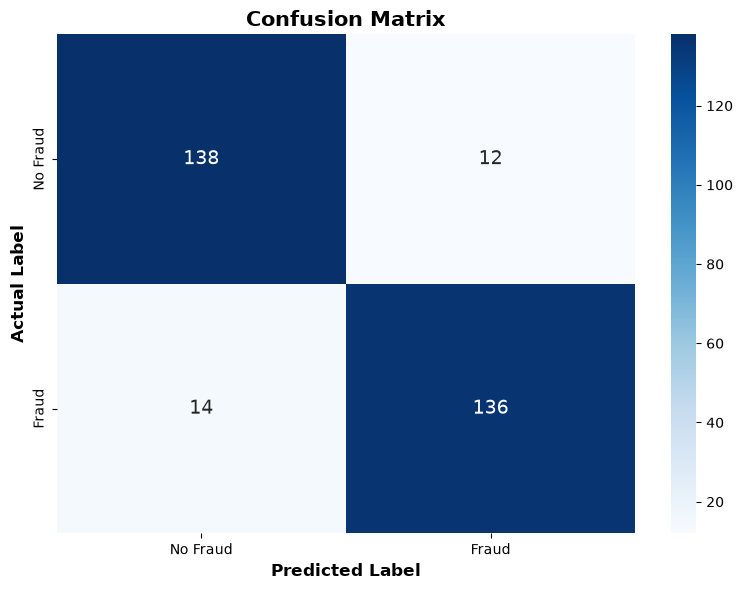

In [63]:
# ------------------------------------------------
# 7. CONFUSION MATRIX
# ------------------------------------------------

import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)


plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Fraud", "Fraud"],
    yticklabels=["No Fraud", "Fraud"],
    annot_kws={"size": 14}
)

plt.title("Confusion Matrix",
          fontsize=15, fontweight="bold")
plt.xlabel("Predicted Label", fontsize=12, fontweight="bold")
plt.ylabel("Actual Label", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


# ACCURACY LOSS CURVES

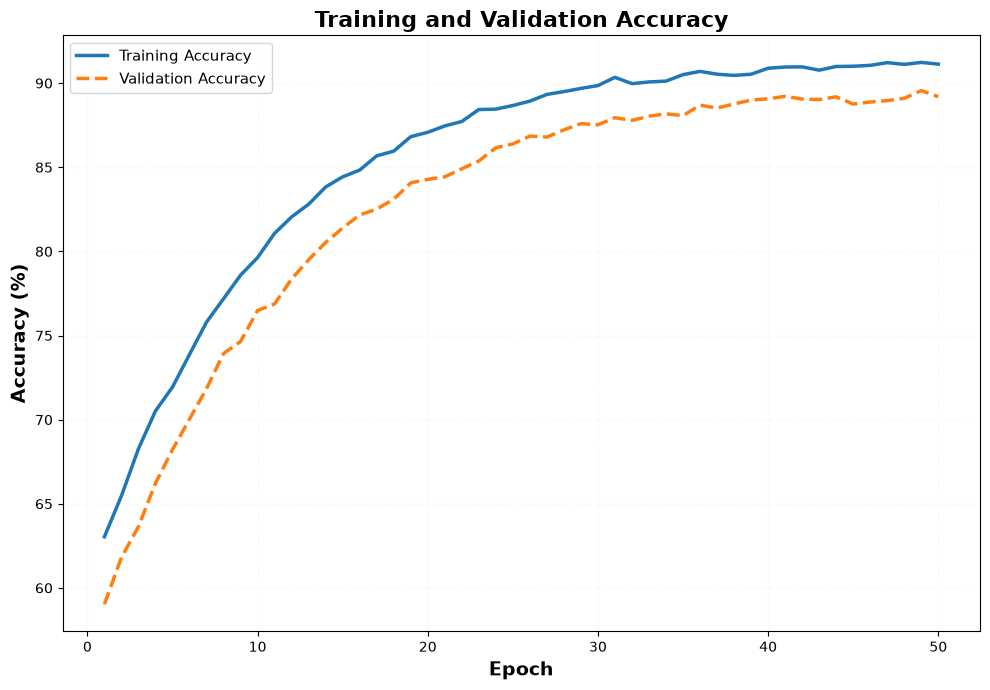

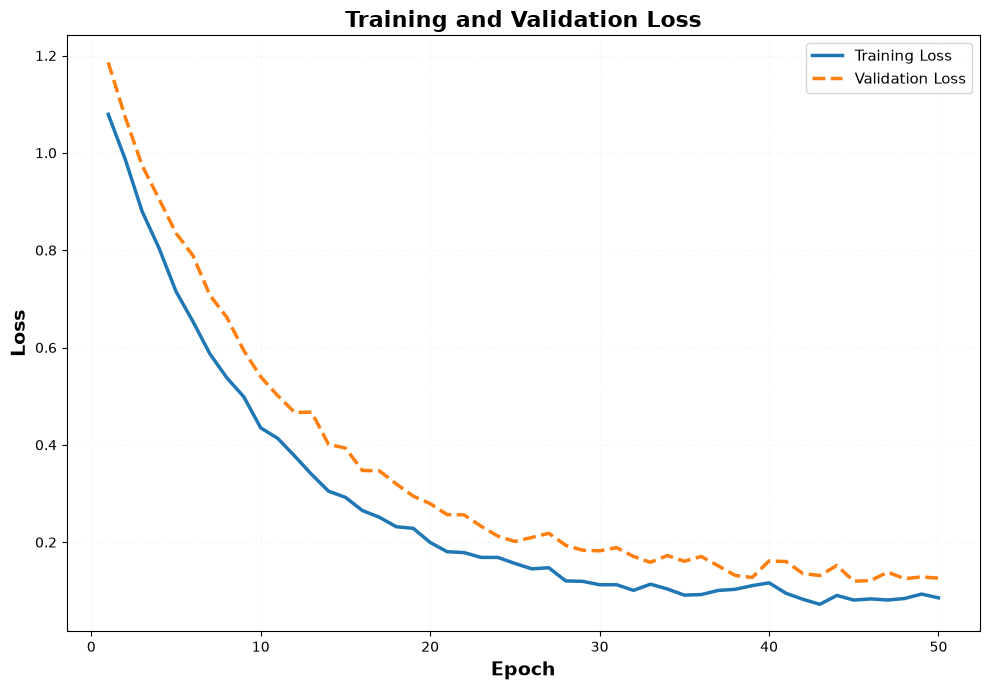

In [55]:

# ================================================================
# ACCURACY VS EPOCH AND LOSS VS EPOCH
# Epoch-based XGBoost model
# ================================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, log_loss

warnings.filterwarnings("ignore")

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

OUTPUT_DIR = r"E:\Projects\2_Financial Fraud\Output"
TARGET = "Fraud_Label"
ID_COL = "Company_ID"
EPOCHS = 20

# ------------------------------------------------
# 2. LOAD DATA
# ------------------------------------------------

train_df = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "multimodal_fused_train_fraud_dataset.csv"
    )
)

val_df = pd.read_csv(
    os.path.join(
        OUTPUT_DIR,
        "multimodal_fused_validation_fraud_dataset.csv"
    )
)


def prepare_xy(df):
    X = df.drop(
        columns=[TARGET, ID_COL],
        errors="ignore"
    ).apply(pd.to_numeric, errors="raise")

    y = df[TARGET].copy()

    if not pd.api.types.is_numeric_dtype(y):
        y = y.astype(str).str.strip().str.lower().map({
            "no fraud": 0,
            "fraud": 1
        })

    if y.isna().any():
        raise ValueError("Invalid target labels.")

    return X, y.astype(int)


X_train, y_train = prepare_xy(train_df)
X_val, y_val = prepare_xy(val_df)

if list(X_train.columns) != list(X_val.columns):
    raise ValueError("Training and validation features do not match.")

# ------------------------------------------------
# 3. TRAIN XGBOOST AND RECORD EACH BOOSTING ROUND
# ------------------------------------------------

model = XGBClassifier(
    n_estimators=EPOCHS,
    learning_rate=0.01,
    max_depth=3,
    subsample=1.0,
    colsample_bytree=0.9,
    min_child_weight=3,
    objective="binary:logistic",
    eval_metric=["logloss", "error"],
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_val, y_val)
    ],
    verbose=False
)

# ------------------------------------------------
# 4. EXTRACT TRAINING AND VALIDATION METRICS
# ------------------------------------------------

results = model.evals_result()

train_loss = results["validation_0"]["logloss"]
val_loss = results["validation_1"]["logloss"]

train_error = results["validation_0"]["error"]
val_error = results["validation_1"]["error"]

epochs = np.arange(1, len(train_loss) + 1)

train_accuracy = 1 - np.array(train_error)
val_accuracy = 1 - np.array(val_error)

# Save actual curve values
curve_df = pd.DataFrame({
    "Epoch": epochs,
    "Training Accuracy": train_accuracy,
    "Validation Accuracy": val_accuracy,
    "Training Loss": train_loss,
    "Validation Loss": val_loss
})

# ------------------------------------------------
# 5. ACCURACY VS EPOCH
# ------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    epochs, train_accuracy,
    linewidth=2, label="Training Accuracy"
)

plt.plot(
    epochs, val_accuracy,
    linewidth=2, label="Validation Accuracy"
)

plt.xlabel("Epoch", fontsize=12, fontweight="bold")
plt.ylabel("Accuracy", fontsize=12, fontweight="bold")
plt.title(
    "Training vs Validation Accuracy",
    fontsize=14, fontweight="bold"
)
plt.grid(True, linestyle=":", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 6. LOSS VS EPOCH
# ------------------------------------------------

plt.figure(figsize=(9, 6))

plt.plot(
    epochs, train_loss,
    linewidth=2, label="Training Loss"
)

plt.plot(
    epochs, val_loss,
    linewidth=2, label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12, fontweight="bold")
plt.ylabel("Log Loss", fontsize=12, fontweight="bold")
plt.title(
    "Training cs Validation Loss",
    fontsize=14, fontweight="bold"
)
plt.grid(True, linestyle=":", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()
